
Overview of The Dataset: 
Dataset shape: (299, 13)
       age  anaemia  creatinine_phosphokinase  diabetes  ejection_fraction  \
0 75.0000        0                       582         0                 20   
1 55.0000        0                      7861         0                 38   
2 65.0000        0                       146         0                 20   
3 50.0000        1                       111         0                 20   
4 65.0000        1                       160         1                 20   

   high_blood_pressure   platelets  serum_creatinine  serum_sodium  sex  \
0                    1 265000.0000            1.9000           130    1   
1                    0 263358.0300            1.1000           136    1   
2                    0 162000.0000            1.3000           129    1   
3                    0 210000.0000            1.9000           137    1   
4                    0 327000.0000            2.7000           116    0   

   smoking  time  DEATH_EVENT  
0

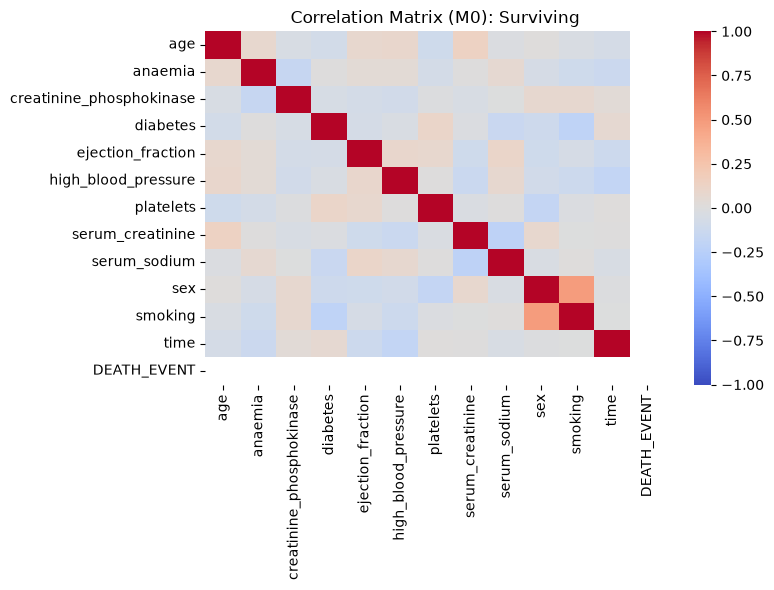

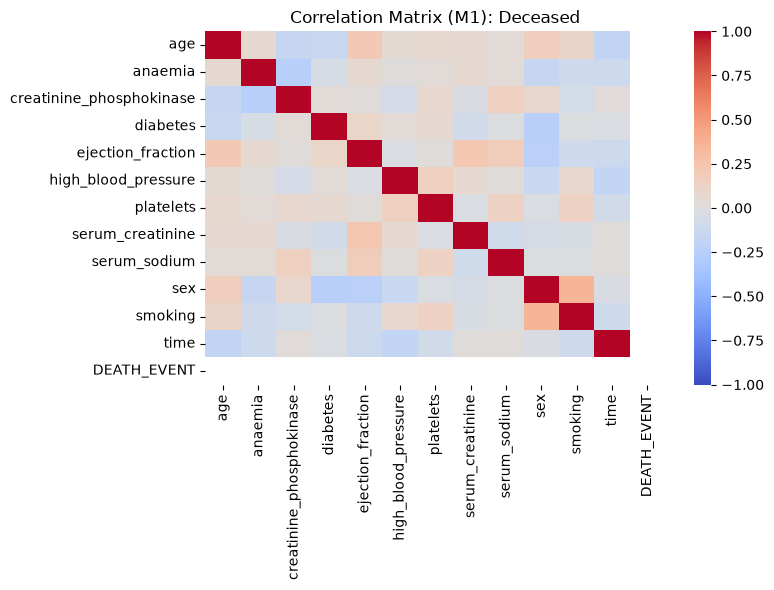


Observations:
For surviving patients, the highest correlation is between sex and smoking, while the lowest correlation
is between smoking and diabetes.
For deceased patients, the highest correlation is also sex and smoking, whereas the lowest correlation
is between sex and diabetes, as well as between anaemia and creatinine phosphokinase (CPK).

The results of highest correlation features are the same for both surviving and deceased patients.
However, the results of lowest correlation features are different across the two groups.

Surviving Patients:
Model: Linear 
Weights: [11.5099], Intercept: 269296.55875755096 
SSE Loss: 838678565058.1346

Model: Quadratic 
Weights: [ 0.     52.8265 -0.0114], Intercept: 257419.77210412727 
SSE Loss: 897096734788.2267

Model: Cubic 
Weights: [ 0.     0.     0.021 -0.   ], Intercept: 268712.77286522585 
SSE Loss: 877896233489.8698

Model: Log 
Weights: [13936.4629], Intercept: 197412.03165230813 
SSE Loss: 877396945760.3381

Model: Loglog 
Weights: 

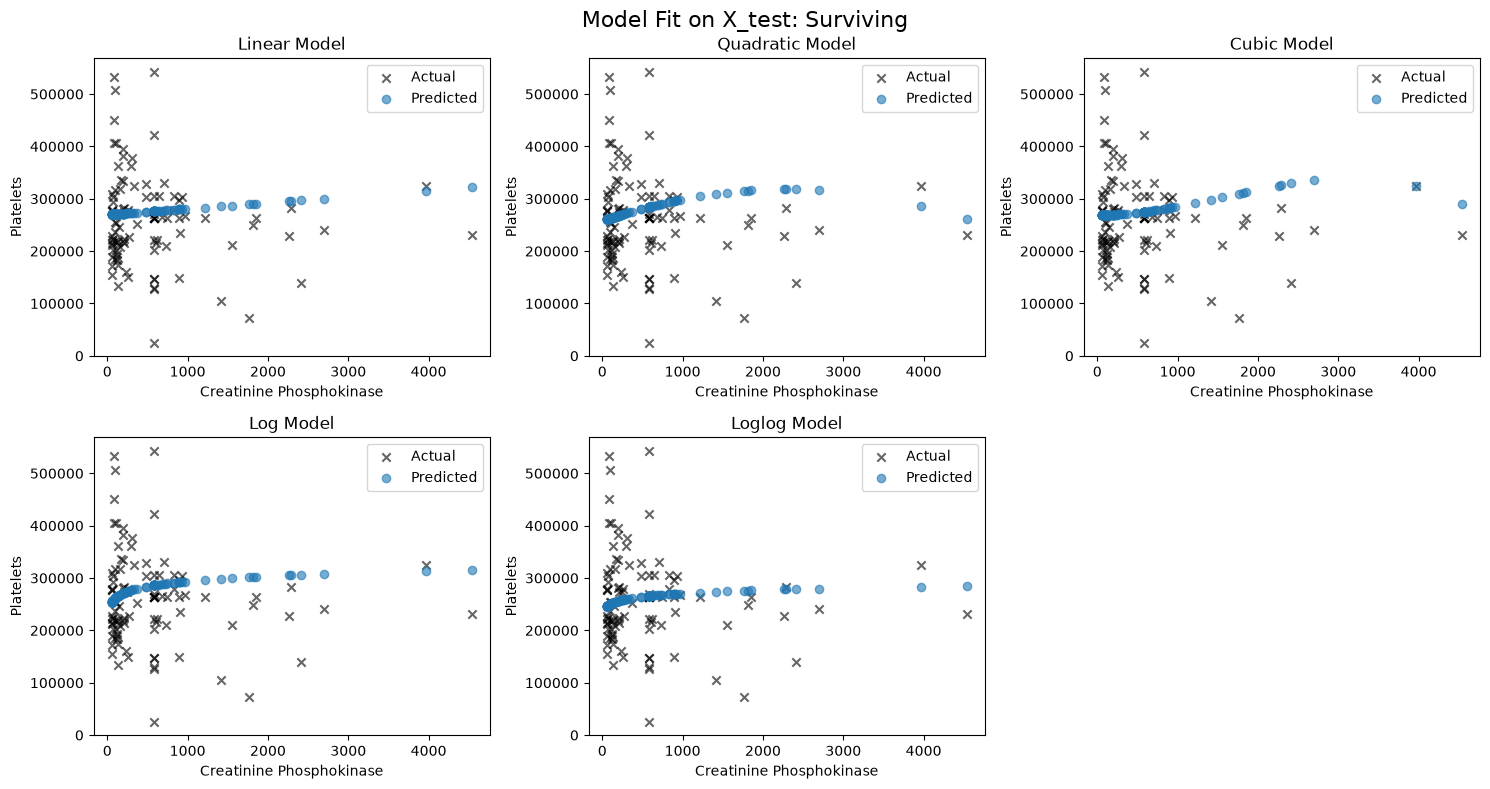


Deceased Patients:
Model: Linear 
Weights: [-1.6955], Intercept: 267828.3335514813 
SSE Loss: 427202337974.7863

Model: Quadratic 
Weights: [ 0.     -6.6349  0.0007], Intercept: 269422.98471123073 
SSE Loss: 425861311464.3452

Model: Cubic 
Weights: [ 0.     -0.     -0.0009  0.    ], Intercept: 267362.92362904514 
SSE Loss: 426121158396.6603

Model: Log 
Weights: [-6398.6405], Intercept: 302768.93522307253 
SSE Loss: 434898903755.0516

Model: Loglog 
Weights: [-0.0144], Intercept: 12.495574220975792 
SSE Loss: 409572269989.4066



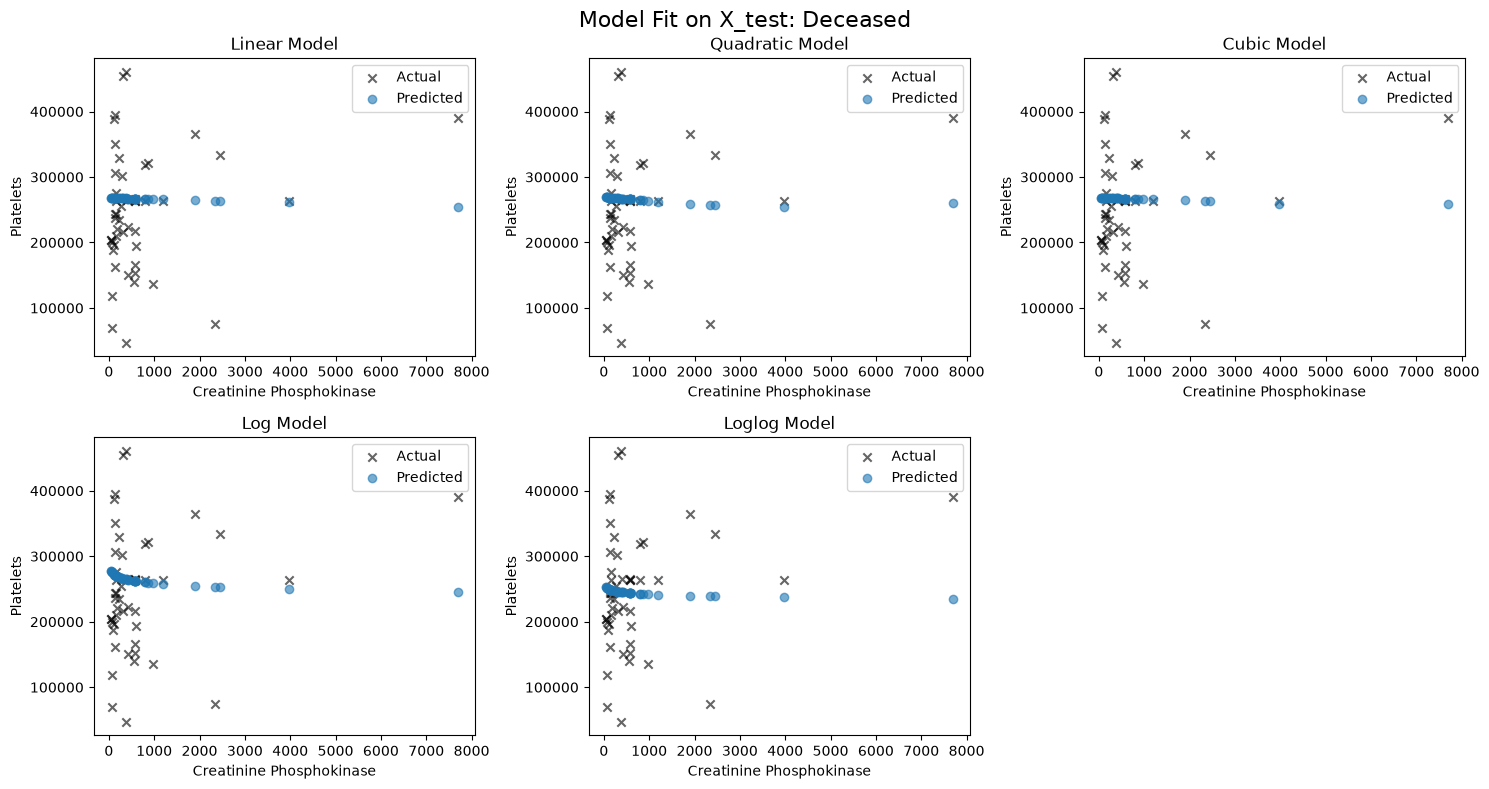

SSE Table
                     Model  SSE (death_event=0)  SSE (death_event=1)
0              y = ax + b    838678565058.1346    427202337974.7863
1        y = ax² + bx + c    897096734788.2267    425861311464.3452
2  y = ax³ + bx² + cx + d    877896233489.8698    426121158396.6603
3        y = a*log(x) + b    877396945760.3381    434898903755.0516
4   log(y) = a*log(x) + b    814530186574.1467    409572269989.4066

Best Models (Smallest SSE):
For surviving patients: log(y) = a*log(x) + b, (SSE = 814530186574.15)
For deceased patients: log(y) = a*log(x) + b (SSE = 409572269989.41)

Worst Models (Largest SSE):
For surviving patients: y = ax² + bx + c (SSE = 897096734788.23)
For deceased patients: y = a*log(x) + b (SSE = 434898903755.05)


In [1]:
import sys
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures


# ANSI escape code for output formatting
BOLD = "\033[1m" if "idlelib" not in sys.modules else ""
RESET = "\033[0m" if "idlelib" not in sys.modules else ""

# set global numeric print format: disable sci-notation, 4 decimals
np.set_printoptions(suppress=True, precision=4)
pd.set_option('display.float_format', '{:.4f}'.format)

"""
Plot the correlation matrices for both surviving and deceased patients,
and examine the correlations between features
"""
# load dataset and preprocessing
df = pd.read_csv('heart_failure_clinical_records_dataset.csv')
print(f'\n{BOLD}Overview of The Dataset:{RESET}',
      f'\nDataset shape: {df.shape}\n',
      df.head())

if df.isnull().sum().sum() == 0:
    pass
else:
    df.dropna(inplace=True)
    print('Rows containing null values have been dropped.')


df_0 = df[df['DEATH_EVENT'] == 0]   # surviving
df_1 = df[df['DEATH_EVENT'] == 1]   # deceased


def correlation_matrix(data, title):
    corr_matrix = data.corr().astype(float)
    plt.figure(figsize=(8, 6))
    sns.heatmap(corr_matrix, annot=False, cmap='coolwarm', vmin=-1, vmax=1)
    plt.title(title)
    plt.tight_layout()
    plt.show()

# plot correlation matrices
correlation_matrix(df_0, 'Correlation Matrix (M0): Surviving')
correlation_matrix(df_1, 'Correlation Matrix (M1): Deceased')

print(f'\n{BOLD}Observations:{RESET}'
      '\nFor surviving patients, the highest correlation is between sex and smoking, while the lowest correlation'
      '\nis between smoking and diabetes.'
      '\nFor deceased patients, the highest correlation is also sex and smoking, whereas the lowest correlation'
      '\nis between sex and diabetes, as well as between anaemia and creatinine phosphokinase (CPK).'
      '\n\nThe results of highest correlation features are the same for both surviving and deceased patients.'
      '\nHowever, the results of lowest correlation features are different across the two groups.')


"""
Model the relationship between creatinine phosphokinase (CPK) and platelets using linear systems
evaluate each model using SSE and predicted vs. actual plots
"""
def linear_model(X, y, model_type, test_size=0.5, seed=77):

    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=test_size, random_state=seed)

    if model_type == 'linear':
        model = LinearRegression()
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
        coef, intercept = model.coef_, model.intercept_

    elif model_type == 'quadratic':
        poly = PolynomialFeatures(degree=2)
        X_train_poly = poly.fit_transform(X_train)
        X_test_poly = poly.transform(X_test)
        model = LinearRegression().fit(X_train_poly, y_train)
        y_pred = model.predict(X_test_poly)
        coef, intercept = model.coef_, model.intercept_

    elif model_type == 'cubic':
        poly = PolynomialFeatures(degree=3)
        X_train_poly = poly.fit_transform(X_train)
        X_test_poly = poly.transform(X_test)
        model = LinearRegression().fit(X_train_poly, y_train)
        y_pred = model.predict(X_test_poly)
        coef, intercept = model.coef_, model.intercept_

    elif model_type == 'log':
        X_train_log = np.log(X_train)
        X_test_log = np.log(X_test)
        model = LinearRegression().fit(X_train_log, y_train)
        y_pred = model.predict(X_test_log)
        coef, intercept = model.coef_, model.intercept_

    elif model_type == 'loglog':
        X_train_log = np.log(X_train)
        y_train_log = np.log(y_train)
        X_test_log = np.log(X_test)
        model = LinearRegression().fit(X_train_log, y_train_log)
        y_pred_log = model.predict(X_test_log)
        y_pred = np.exp(y_pred_log)
        coef, intercept = model.coef_, model.intercept_

    else:
        raise ValueError("Unrecognized model type.")

    # loss function SSE
    sse = np.sum((y_test - y_pred) ** 2)

    print(f"Model: {model_type.capitalize()}",
          f"\nWeights: {coef}, Intercept: {intercept}",
          f"\nSSE Loss: {sse:.4f}\n")

    return X_test, y_test, y_pred, sse


models = ['linear', 'quadratic', 'cubic', 'log', 'loglog']

sse_table = {
    'Model': [],
    'SSE (death_event=0)': [],
    'SSE (death_event=1)': []
}

# print and plot results
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

print(f'\n{BOLD}Surviving Patients:{RESET}')
for i, model in enumerate(models):
    X_0 = df_0[['creatinine_phosphokinase']].values
    y_0 = df_0['platelets'].values
    X_test, y_test, y_pred, sse = linear_model(X_0, y_0, model)
    sse_table['Model'].append(model)
    sse_table['SSE (death_event=0)'].append(sse)

    ax = axes[i]
    ax.scatter(X_test, y_test, color='black', marker='x', label='Actual', alpha=0.6)
    ax.scatter(X_test, y_pred, label='Predicted', alpha=0.6)
    ax.set_title(f'{model.capitalize()} Model')
    ax.set_xlabel('Creatinine Phosphokinase')
    ax.set_ylabel('Platelets')
    ax.legend()

fig.delaxes(axes[-1])
fig.suptitle('Model Fit on X_test: Surviving', fontsize=16)
plt.tight_layout()
plt.subplots_adjust(top=0.92)
plt.show()


fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

print(f'\n{BOLD}Deceased Patients:{RESET}')
for i, model in enumerate(models):
    X_1 = df_1[['creatinine_phosphokinase']].values
    y_1 = df_1['platelets'].values
    X_test, y_test, y_pred, sse = linear_model(X_1, y_1, model)
    sse_table['SSE (death_event=1)'].append(sse)

    ax = axes[i]
    ax.scatter(X_test, y_test, color='black', marker='x', label='Actual', alpha=0.6)
    ax.scatter(X_test, y_pred, label='Predicted', alpha=0.6)
    ax.set_title(f'{model.capitalize()} Model')
    ax.set_xlabel('Creatinine Phosphokinase')
    ax.set_ylabel('Platelets')
    ax.legend()

fig.delaxes(axes[-1])
fig.suptitle('Model Fit on X_test: Deceased', fontsize=16)
plt.tight_layout()
plt.subplots_adjust(top=0.92)
plt.show()

"""
Summarize the results into table
"""
model_labels = {
    'linear': 'y = ax + b',
    'quadratic': 'y = ax² + bx + c',
    'cubic': 'y = ax³ + bx² + cx + d',
    'log': 'y = a*log(x) + b',
    'loglog': 'log(y) = a*log(x) + b'
}
sse_df = pd.DataFrame(sse_table)
sse_df['Model'] = sse_df['Model'].map(model_labels)

# retrieve best and worst models
best_model_0 = sse_df.loc[sse_df['SSE (death_event=0)'].idxmin()]
best_model_1 = sse_df.loc[sse_df['SSE (death_event=1)'].idxmin()]
worst_model_0 = sse_df.loc[sse_df['SSE (death_event=0)'].idxmax()]
worst_model_1 = sse_df.loc[sse_df['SSE (death_event=1)'].idxmax()]


print(f'{BOLD}SSE Table{RESET}\n', sse_df)
print(f'\nBest Models (Smallest SSE):'
      f"\nFor surviving patients: {best_model_0['Model']}, (SSE = {best_model_0['SSE (death_event=0)']:.2f})"
      f"\nFor deceased patients: {best_model_1['Model']} (SSE = {best_model_1['SSE (death_event=1)']:.2f})"

      f'\n\nWorst Models (Largest SSE):'
      f"\nFor surviving patients: {worst_model_0['Model']} (SSE = {worst_model_0['SSE (death_event=0)']:.2f})"
      f"\nFor deceased patients: {worst_model_1['Model']} (SSE = {worst_model_1['SSE (death_event=1)']:.2f})")